# Week 13 — Ultrasound speckle: statistics, median filtering, compounding, and speckle tracking

Tissue contains many sub-resolution scatterers. Their echoes interfere inside every resolution cell, producing **speckle**: a granular texture that is **not** an image of the anatomy, but it is **stable** between frames when the tissue moves only slightly. That makes speckle both

* a **nuisance** (it lowers contrast-to-noise ratio; filtering and compounding can reduce it), and
* a **natural marker** (like MRI tags): block-matching speckle between frames estimates **motion and strain**.

Sections: (1) why speckle is Rayleigh distributed and has a fixed SNR of about 1.91; (2) a simulated B-mode phantom (cyst, bright lesion, point targets); (3) **median filter** vs Gaussian filter (CNR and resolution trade-off); (4) **compounding** ($\sqrt N$ gain); (5) **speckle tracking** to recover displacement and strain.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve, hilbert
from scipy.ndimage import median_filter, gaussian_filter
from skimage.feature import match_template

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False})
rng = np.random.default_rng(1)

## 1. Random phasor sums give Rayleigh amplitudes

One pixel's complex echo is the sum of $n$ scatterer contributions with random phase. For small $n$ the amplitude is irregular; once $n$ is large ("fully developed speckle"), the amplitude follows a **Rayleigh** distribution with
$$\text{SNR}_{speckle}=\frac{\mu}{\sigma}=\sqrt{\frac{\pi}{4-\pi}}\approx1.91,$$
independent of the scatterer density. So no amount of extra scatterers improves the speckle SNR; the only fixes are filtering, compounding, or averaging independent looks.

 n scatterers  mean/std
            1      1.32
            2      1.61
            5      1.80
           20      1.89
          100      1.91
Rayleigh theory: 1.913


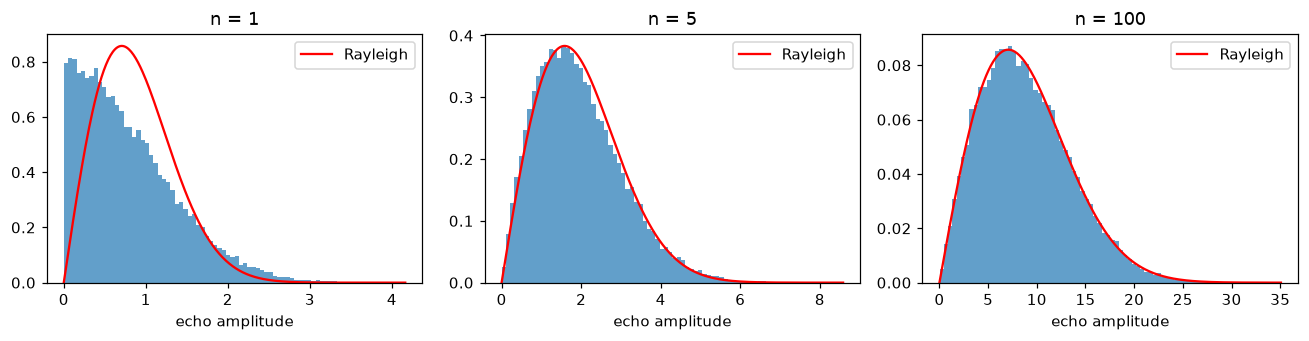

In [2]:
trials = 40000
ns = [1, 2, 5, 20, 100]
amps_by_n = {}
for n in ns:
    ph = rng.uniform(0, 2 * np.pi, (trials, n))
    a = rng.normal(size=(trials, n))                    # random scatterer strengths
    amps_by_n[n] = np.abs((a * np.exp(1j * ph)).sum(axis=1))

print(f"{'n scatterers':>13s} {'mean/std':>9s}")
for n in ns:
    A = amps_by_n[n]
    print(f"{n:13d} {A.mean()/A.std():9.2f}")
print("Rayleigh theory:", round(np.sqrt(np.pi / (4 - np.pi)), 3))

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, n in zip(ax, (1, 5, 100)):
    A = amps_by_n[n]
    a.hist(A, bins=80, density=True, alpha=0.7)
    s = np.sqrt(np.mean(A ** 2) / 2)
    xx = np.linspace(0, A.max(), 300)
    a.plot(xx, xx / s ** 2 * np.exp(-xx ** 2 / (2 * s ** 2)), 'r', label='Rayleigh')
    a.set(title=f'n = {n}', xlabel='echo amplitude'); a.legend()
plt.tight_layout(); plt.show()

## 2. A simulated B-mode phantom with speckle

Scatterers are placed at random positions with random amplitudes, scaled by the local reflectivity: background 1, an **anechoic cyst** 0, a **bright lesion** 3. Three bright **point targets** show resolution. The RF image is the scatterer map convolved with a pulse-echo PSF (an oscillating pulse axially, a narrower Gaussian laterally), then envelope detection (Hilbert transform) and log compression give the B-mode image.

Distances are in pixels; the carrier period is 6 px, the axial envelope width $\sigma_z=3$ px, and the lateral width $\sigma_x=4$ px.

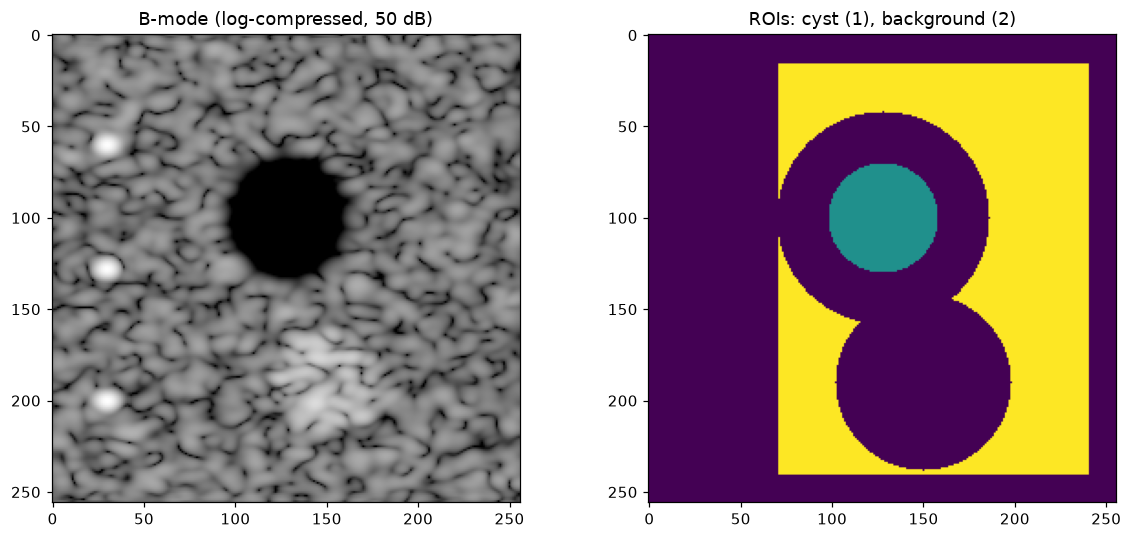

background envelope speckle SNR (mean/std): 1.98  (Rayleigh: 1.91)


In [3]:
H = W = 256
zz, xx = np.mgrid[-12:13, -12:13]
psf = np.exp(-zz ** 2 / (2 * 3.0 ** 2)) * np.cos(2 * np.pi * zz / 6.0) * np.exp(-xx ** 2 / (2 * 4.0 ** 2))

cyst_c, cyst_r = (100, 128), 38
bright_c, bright_r = (190, 150), 28
points = np.array([[60, 30], [128, 30], [200, 30]], float)

def reflectivity(pos):
    r = np.ones(len(pos))
    r[np.hypot(pos[:, 0] - cyst_c[0], pos[:, 1] - cyst_c[1]) < cyst_r] = 0.0
    r[np.hypot(pos[:, 0] - bright_c[0], pos[:, 1] - bright_c[1]) < bright_r] = 3.0
    return r

def splat(pos, amp, shape):
    """Bilinear accumulation of scatterers (z, x in pixel units) onto a grid."""
    img = np.zeros(shape)
    z, x = pos[:, 0], pos[:, 1]
    z0 = np.floor(z).astype(int); x0 = np.floor(x).astype(int)
    fz, fx = z - z0, x - x0
    for dz, dx, wgt in ((0, 0, (1 - fz) * (1 - fx)), (1, 0, fz * (1 - fx)),
                        (0, 1, (1 - fz) * fx), (1, 1, fz * fx)):
        zi, xi = z0 + dz, x0 + dx
        ok = (zi >= 0) & (zi < shape[0]) & (xi >= 0) & (xi < shape[1])
        np.add.at(img, (zi[ok], xi[ok]), (amp * wgt)[ok])
    return img

def envelope_from_scatterers(pos, amp, shape=(H, W)):
    rf = fftconvolve(splat(pos, amp, shape), psf, mode='same')
    return np.abs(hilbert(rf, axis=0))

def render_phantom(seed, M=200000):
    r = np.random.default_rng(seed)
    pos = r.uniform([0, 0], [H, W], (M, 2))
    amp = r.normal(size=M) * reflectivity(pos)
    pos = np.vstack([pos, points]); amp = np.concatenate([amp, np.full(len(points), 150.0)])
    return envelope_from_scatterers(pos, amp)

def log_compress(env, dyn=50):
    db = 20 * np.log10(env / env.max() + 1e-9)
    return np.maximum(db, -dyn)

env0 = render_phantom(10)
bmode0 = log_compress(env0)

# ROIs: cyst interior, a clean background patch away from the lesions and the point targets
Y, Xg = np.mgrid[0:H, 0:W]
cyst_roi = np.hypot(Y - cyst_c[0], Xg - cyst_c[1]) < cyst_r - 8
bg_roi = ((np.hypot(Y - cyst_c[0], Xg - cyst_c[1]) > cyst_r + 20) &
          (np.hypot(Y - bright_c[0], Xg - bright_c[1]) > bright_r + 20) &
          (Xg > 70) & (Xg < W - 15) & (Y > 15) & (Y < H - 15))

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(bmode0, cmap='gray', vmin=-50, vmax=0); ax[0].set_title('B-mode (log-compressed, 50 dB)')
ax[1].imshow(np.where(cyst_roi, 1, 0) + 2 * np.where(bg_roi, 1, 0), cmap='viridis'); ax[1].set_title('ROIs: cyst (1), background (2)')
plt.tight_layout(); plt.show()

print(f"background envelope speckle SNR (mean/std): {env0[bg_roi].mean()/env0[bg_roi].std():.2f}  (Rayleigh: 1.91)")

## 3. Median vs Gaussian filtering

A **median filter** replaces each pixel with the median of its neighbourhood. It is a simple statistical filter that handles the salt-and-pepper character of speckle and preserves edges better than a mean/Gaussian filter of the same smoothing. We apply it to the log-compressed image and score:

* **CNR** between the cyst and the background: $\mathrm{CNR}=|\mu_b-\mu_c|/\sqrt{\sigma_b^2+\sigma_c^2}$;
* the **peak brightness of a point target** (what fraction of resolution is lost).

          filter    CNR  bg std (dB)  point peak (dB)
             raw   4.11         5.56             -0.3
      median 3x3   4.71         4.91             -0.8
      median 5x5   5.44         4.29             -1.7
      median 9x9   7.11         3.32             -4.8
  gaussian s=1.5   5.19         4.38             -1.9
    gaussian s=3   7.00         3.13             -7.0


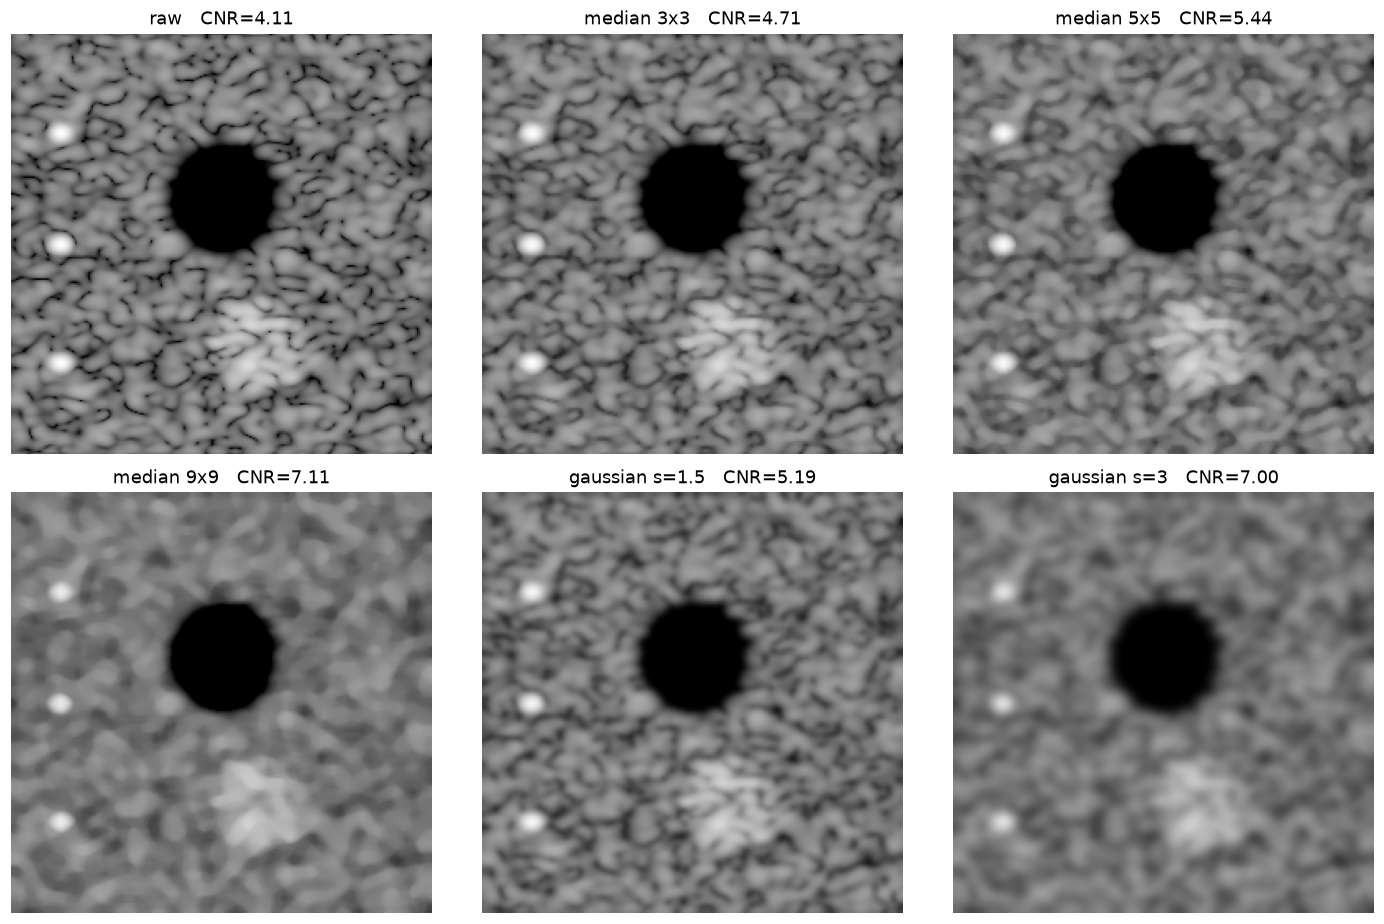

In [4]:
def cnr(img):
    mb, mc = img[bg_roi].mean(), img[cyst_roi].mean()
    return abs(mb - mc) / np.sqrt(img[bg_roi].var() + img[cyst_roi].var())

def point_peak(img):
    z, x = points[1].astype(int)
    return img[z - 3:z + 4, x - 3:x + 4].max()

filters = {
    'raw': bmode0,
    'median 3x3': median_filter(bmode0, 3),
    'median 5x5': median_filter(bmode0, 5),
    'median 9x9': median_filter(bmode0, 9),
    'gaussian s=1.5': gaussian_filter(bmode0, 1.5),
    'gaussian s=3': gaussian_filter(bmode0, 3),
}
print(f"{'filter':>16s} {'CNR':>6s} {'bg std (dB)':>12s} {'point peak (dB)':>16s}")
for name, im in filters.items():
    print(f"{name:>16s} {cnr(im):6.2f} {im[bg_roi].std():12.2f} {point_peak(im):16.1f}")

fig, axs = plt.subplots(2, 3, figsize=(13, 8.5))
for ax, (name, im) in zip(axs.ravel(), filters.items()):
    ax.imshow(im, cmap='gray', vmin=-50, vmax=0); ax.set_title(f'{name}   CNR={cnr(im):.2f}'); ax.axis('off')
plt.tight_layout(); plt.show()

Smoothing raises CNR, but a large kernel starts to **erase small bright structures** (the point targets) and blur edges: the same noise vs resolution trade-off seen in the first weeks of the course. In the table above, the 9x9 median and the Gaussian with $\sigma=3$ reach a similar CNR, but the median keeps the point target brighter (a smaller dB loss), which is the practical argument for rank filters on speckle.

## 4. Compounding independent looks

If several images of the same anatomy have **independent speckle** (different frequencies, steering angles, or apertures in practice), averaging $N$ of them raises the speckle SNR by $\sqrt N$ without blurring. Here each "look" has the same reflectivity but a new random scatterer realization, an idealization of perfectly decorrelated speckle.

N =  1: speckle SNR = 1.88   (theory 1.91*sqrt(N) = 1.91)
N =  2: speckle SNR = 2.64   (theory 1.91*sqrt(N) = 2.70)
N =  4: speckle SNR = 3.81   (theory 1.91*sqrt(N) = 3.82)
N =  8: speckle SNR = 5.41   (theory 1.91*sqrt(N) = 5.40)
N = 16: speckle SNR = 7.67   (theory 1.91*sqrt(N) = 7.64)


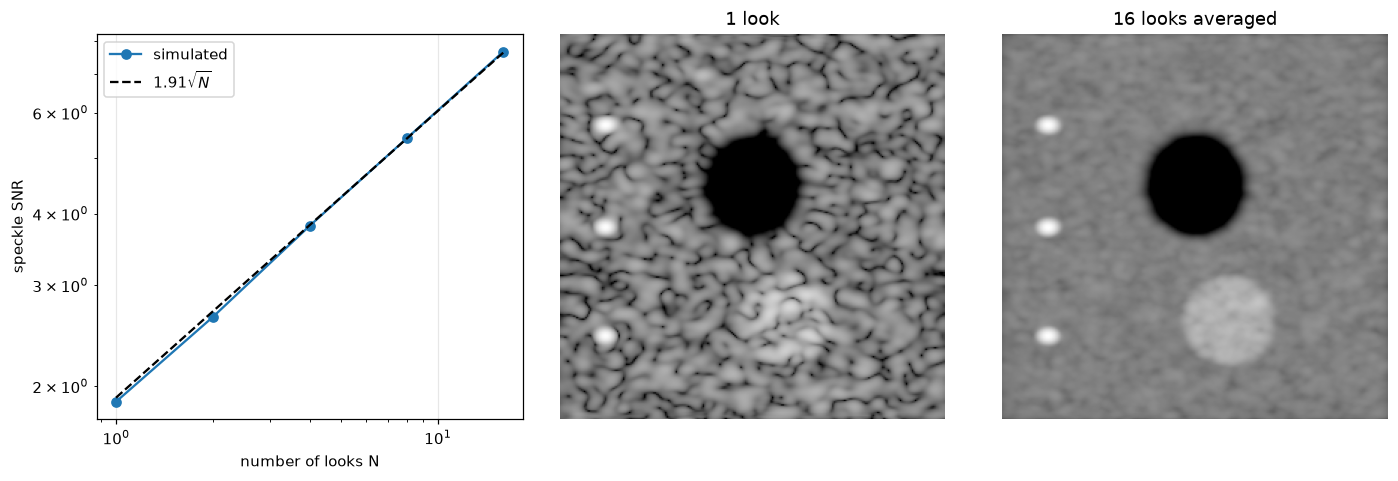

In [5]:
Ns = [1, 2, 4, 8, 16]
looks = [render_phantom(100 + i) for i in range(max(Ns))]
snrs = []
for N in Ns:
    avg = np.mean(looks[:N], axis=0)
    snrs.append(avg[bg_roi].mean() / avg[bg_roi].std())
    print(f"N = {N:2d}: speckle SNR = {snrs[-1]:.2f}   (theory 1.91*sqrt(N) = {1.91*np.sqrt(N):.2f})")

fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
ax[0].loglog(Ns, snrs, 'o-', label='simulated')
ax[0].loglog(Ns, 1.91 * np.sqrt(Ns), 'k--', label=r'$1.91\sqrt{N}$')
ax[0].set(xlabel='number of looks N', ylabel='speckle SNR'); ax[0].legend(); ax[0].grid(True, alpha=0.3)
ax[1].imshow(log_compress(looks[0]), cmap='gray', vmin=-50, vmax=0); ax[1].set_title('1 look'); ax[1].axis('off')
ax[2].imshow(log_compress(np.mean(looks, axis=0)), cmap='gray', vmin=-50, vmax=0); ax[2].set_title('16 looks averaged'); ax[2].axis('off')
plt.tight_layout(); plt.show()

## 5. Speckle tracking: speckle as a natural tag

Because speckle moves with the tissue, a small **block** of the first frame can be located in the second frame by maximizing the **normalized cross-correlation (NCC)**. We deform a uniform speckle field with a known displacement
$$u_z = 1.5 - 0.02\,(z-z_c),\qquad u_x = -2.0 + 0.03\,(x-x_c)\quad(\text{pixels}),$$
i.e., a translation plus a $+3\%$ lateral stretch and a $-2\%$ axial compression. Block matching with sub-pixel peak interpolation then recovers the displacement field, and the **strain** is its spatial derivative.

169 blocks; median NCC peak = 0.98
axial   displacement error: mean -0.003, RMS 0.093 px
lateral displacement error: mean -0.037, RMS 0.138 px
lateral strain: true +0.0300, estimated +0.0301
axial   strain: true -0.0200, estimated -0.0202


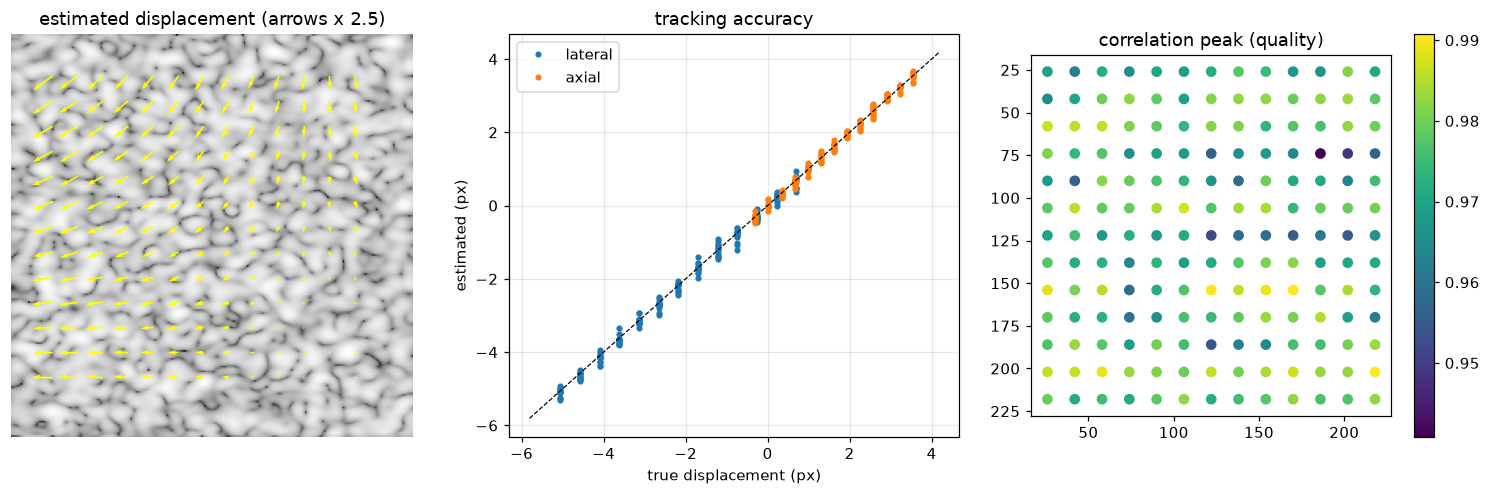

In [6]:
M = 150000
P0 = rng.uniform([0, 0], [H, W], (M, 2))
A0 = rng.normal(size=M)
zc, xc = H / 2, W / 2
uz0, ux0, ez, ex = 1.5, -2.0, -0.02, 0.03

def displacement(pos):
    return np.stack([uz0 + ez * (pos[:, 0] - zc), ux0 + ex * (pos[:, 1] - xc)], axis=1)

P1 = P0 + displacement(P0)
A1 = A0 * (1 + 0.05 * rng.normal(size=M))              # a little decorrelation between frames
frame0 = envelope_from_scatterers(P0, A0)
frame1 = envelope_from_scatterers(P1, A1)

def track(f0img, f1img, bs=32, search=10, step=16):
    half = bs // 2
    zs = np.arange(half + search, H - half - search, step)
    xs = np.arange(half + search, W - half - search, step)
    out = []
    for z in zs:
        for x in xs:
            tpl = f0img[z - half:z + half, x - half:x + half]
            reg = f1img[z - half - search:z + half + search, x - half - search:x + half + search]
            ncc = match_template(reg, tpl)
            iz, ix = np.unravel_index(ncc.argmax(), ncc.shape)
            sz = sx = 0.0
            if 0 < iz < ncc.shape[0] - 1:
                den = ncc[iz - 1, ix] - 2 * ncc[iz, ix] + ncc[iz + 1, ix]
                sz = 0.5 * (ncc[iz - 1, ix] - ncc[iz + 1, ix]) / den
            if 0 < ix < ncc.shape[1] - 1:
                den = ncc[iz, ix - 1] - 2 * ncc[iz, ix] + ncc[iz, ix + 1]
                sx = 0.5 * (ncc[iz, ix - 1] - ncc[iz, ix + 1]) / den
            out.append((z, x, iz - search + sz, ix - search + sx, ncc.max()))
    return np.array(out)

res = track(frame0, frame1)
zb, xb, dz_est, dx_est, peak = res.T
true = displacement(np.stack([zb, xb], axis=1))
err_z, err_x = dz_est - true[:, 0], dx_est - true[:, 1]
print(f"{len(res)} blocks; median NCC peak = {np.median(peak):.2f}")
print(f"axial   displacement error: mean {err_z.mean():+.3f}, RMS {np.sqrt(np.mean(err_z**2)):.3f} px")
print(f"lateral displacement error: mean {err_x.mean():+.3f}, RMS {np.sqrt(np.mean(err_x**2)):.3f} px")

# strain = slope of displacement vs position
ex_hat = np.polyfit(xb, dx_est, 1)[0]
ez_hat = np.polyfit(zb, dz_est, 1)[0]
print(f"lateral strain: true {ex:+.4f}, estimated {ex_hat:+.4f}")
print(f"axial   strain: true {ez:+.4f}, estimated {ez_hat:+.4f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
ax[0].imshow(log_compress(frame0), cmap='gray', vmin=-50, vmax=0)
ax[0].quiver(xb, zb, dx_est, dz_est, color='yellow', angles='xy', scale_units='xy', scale=0.4, width=0.004)
ax[0].set_title('estimated displacement (arrows x 2.5)'); ax[0].axis('off')
ax[1].plot(true[:, 1], dx_est, '.', label='lateral'); ax[1].plot(true[:, 0], dz_est, '.', label='axial')
lim = [min(true.min(), dz_est.min(), dx_est.min()) - 0.5, max(true.max(), dz_est.max(), dx_est.max()) + 0.5]
ax[1].plot(lim, lim, 'k--', lw=0.8); ax[1].set(xlabel='true displacement (px)', ylabel='estimated (px)', title='tracking accuracy')
ax[1].legend(); ax[1].grid(True, alpha=0.3)
sc = ax[2].scatter(xb, zb, c=peak, cmap='viridis'); ax[2].invert_yaxis(); ax[2].set_title('correlation peak (quality)')
fig.colorbar(sc, ax=ax[2]); ax[2].set_aspect('equal')
plt.tight_layout(); plt.show()

## Summary

* **Speckle** is a coherent-interference pattern: Rayleigh amplitudes with a fixed SNR of about 1.91, whatever the scatterer density.
* A **median filter** (or any smoothing) raises CNR but costs resolution; **compounding** independent looks gives $\sqrt N$ SNR without blurring.
* Speckle is **stable under small motion**, so block matching with NCC recovers displacement, and spatial derivatives give **strain**: the ultrasound analogue of MRI tagging. In practice, large deformation, out-of-plane motion, and speckle decorrelation limit this, so tracking quality maps (as in the last panel) matter.

Related notebooks: [Ultrasound_Beamforming_Aperture](Ultrasound_Beamforming_Aperture.ipynb), [Ultrasound_Doppler](Ultrasound_Doppler.ipynb), and [Week 12 PSF](../Week12/Ultrasound_PSF_Convolution.ipynb).